# Tully-Fisher and the aligned-shear blind spot

**Scope note.** Runs today, like the other demo notebooks. Uses
`kino.galaxy` (Phase 1) and `kino.lensing` (Phase 2) only -- no instrument
or inference yet.

**Motivation.** `02_shear_misalignment_demo.ipynb` showed that the
photometric/kinematic position-angle misalignment -- the most visually
obvious kinematic-lensing signature -- vanishes **exactly** when the shear
happens to be aligned with the disc's own axes
(`test_misalignment_vanishes_when_shear_aligned_with_disc_axes`). That's a
real blind spot for a PA-only estimator. This notebook shows two other
signatures that **do not** vanish in that case, both of which route
through the Tully-Fisher (TF) relation -- the actual mechanism the KL
literature (Huff et al. 2013; Pranjal R. S. et al. 2024/25, arXiv:2409.08367)
uses instead of a bare PA comparison:

1. **Ellipticity magnitude.** Shear aligned with the disc's axes doesn't
   rotate the ellipse, but it does rescale its axis ratio -- the observed
   ellipticity magnitude drifts away from what the (shear-free) kinematics
   predict, even with zero PA misalignment.
2. **Flux magnification.** Pure shear alone magnifies: `mu = 1/(1-|g|^2)`,
   nonzero even with no convergence (`kino.lensing.shear.magnification`,
   added alongside this notebook). If a Tully-Fisher-based estimate of the
   intrinsic rotation velocity uses the *observed* (magnified) flux without
   correcting for it, that's a second, independent bias -- one that also
   depends only on `|g|`, not its orientation, so it's fully present in the
   aligned case too.

**Caveat.** The real KL method needs an actual calibrated TF relation
(slope, zero-point, band, intrinsic scatter) -- none exists in KINO yet
(`README.md` Phase 5 reserves this: "Priors module (Tully-Fisher prior on
rotation...)"). The relation used below is a **toy**, chosen only so the
galaxy sits exactly on it by construction -- useful for isolating the two
effects above cleanly, not a stand-in for real calibration. Do not carry
its constants into a real analysis.

## 0. Setup

In [1]:
import matplotlib.pyplot as plt
import numpy as np

import kino
from kino.galaxy import DiscGalaxy
from kino.lensing import apply_shear
from kino.lensing.shear import magnification

print("kino", kino.__version__)

kino 0.1.0.dev0


## 1. A toy Tully-Fisher relation

`v_flat = v0 * (flux / flux0) ** (1/alpha)` -- calibrated so the galaxy
built in the next cell sits exactly on it (`v0 = gal.v_flat`,
`flux0 = gal.flux`). `alpha` here is just an illustrative NIR-ish slope
(real TF slopes vary by band and calibration, roughly 3-4); nothing below
depends on its exact value being realistic.

In [2]:
ALPHA = 4.0


def tf_velocity(flux, v0, flux0, alpha=ALPHA):
    """Toy Tully-Fisher: intrinsic rotation velocity implied by ``flux``."""
    return v0 * (flux / flux0) ** (1.0 / alpha)

## 2. A galaxy, and a shear aligned with its own axes

Same trick as `02_shear_misalignment_demo.ipynb` section 5: pick `g` with
the same complex phase as the disc's intrinsic ellipticity, so it rotates
nothing. Confirm the misalignment really is (numerically) zero before
relying on it.

In [3]:
gal = DiscGalaxy(r_e=2.0, inc=50.0, pa=15.0, v_flat=200.0, r_t=2.0, flux=5.0)

phi_gal = np.pi / 2.0 - np.radians(gal.pa)
g_mag = 0.3
g_complex = g_mag * np.exp(2j * phi_gal)
g1, g2 = g_complex.real, g_complex.imag

scene = apply_shear(gal, g1, g2)
mag_obs, pa_obs = scene.photometric_ellipticity
misalignment = min(abs(pa_obs - gal.pa), 180 - abs(pa_obs - gal.pa))
print(f"g1={g1:.4f}, g2={g2:.4f}, |g|={g_mag}")
print(f"true pa = {gal.pa} deg, photometric pa = {pa_obs:.6f} deg")
print(f"misalignment = {misalignment:.6f} deg")

g1=-0.2598, g2=0.1500, |g|=0.3
true pa = 15.0 deg, photometric pa = 15.000000 deg
misalignment = 0.000000 deg


## 3. Zero misalignment, nonzero ellipticity shift

The PA lines up (to numerical noise). The ellipticity *magnitude* doesn't:
shear that only rescales the ellipse still changes how elongated it is.

In [4]:
print(f"intrinsic ellipticity:  {gal.ellipticity:.4f}")
print(f"photometric ellipticity: {mag_obs:.4f}  (observed/lensed)")
print(f"difference:              {mag_obs - gal.ellipticity:+.4f}")

intrinsic ellipticity:  0.2174
photometric ellipticity: 0.4858  (observed/lensed)
difference:              +0.2683


## 4. Vmax is shear-invariant (numerically confirmed)

Lensing conserves surface brightness -- and with it, the *value* of
`Vlos` wherever it's sampled, only *where* it's sampled moves. Because the
shear is aligned with the disc here, the major axis line doesn't even
rotate, so evaluating far out along it should recover the plain
(unlensed) rotation-curve asymptote `v_flat * sin(inc)`, shear or no
shear.

In [5]:
v_max_true = gal.v_flat * np.sin(np.radians(gal.inc))

pa_rad = np.radians(gal.pa)
r_far = 200 * gal.r_t  # far enough that arctan(r/r_t) has saturated
x_far = gal.x0 + r_far * np.sin(pa_rad)
y_far = gal.y0 + r_far * np.cos(pa_rad)

v_max_lensed_measurement = float(scene.vlos(x_far, y_far))
v_max_unlensed_measurement = float(gal.vlos(x_far, y_far))

print(f"analytic v_flat * sin(inc):        {v_max_true:.4f} km/s")
print(f"measured on the UNLENSED galaxy:   {v_max_unlensed_measurement:.4f} km/s")
print(f"measured on the LENSED scene:      {v_max_lensed_measurement:.4f} km/s")

analytic v_flat * sin(inc):        153.2089 km/s
measured on the UNLENSED galaxy:   152.7212 km/s
measured on the LENSED scene:      152.5122 km/s


## 5. Flux magnification biases a naive TF prediction

`magnification(g1, g2) = 1/(1-|g|^2)` is exact given `kino.lensing`'s
surface-brightness-conserving forward model (see that function's
docstring). Confirm it numerically too, by actually rendering and
integrating both images, before using it.

In [6]:
mu = magnification(g1, g2)
print(f"analytic magnification mu = 1/(1-|g|^2): {mu:.4f}")

extent = 10 * gal.r_e
coords = np.linspace(-extent, extent, 400)
xg, yg = np.meshgrid(coords, coords)
pixel_area = (coords[1] - coords[0]) ** 2

flux_unlensed = gal.surface_brightness(xg, yg).sum() * pixel_area
flux_lensed = scene.surface_brightness(xg, yg).sum() * pixel_area
mu_numeric = flux_lensed / flux_unlensed

print(f"rendered unlensed flux:  {flux_unlensed:.5f}  (input flux={gal.flux})")
print(f"rendered lensed flux:    {flux_lensed:.5f}")
print(f"numeric flux ratio:      {mu_numeric:.4f}  (vs analytic mu={mu:.4f})")

analytic magnification mu = 1/(1-|g|^2): 1.0989
rendered unlensed flux:  4.99993  (input flux=5.0)
rendered lensed flux:    5.49431
numeric flux ratio:      1.0989  (vs analytic mu=1.0989)


## 6. Two independent, non-vanishing shear signals

Put it together: what a TF-based estimator would predict for the
ellipticity, with and without correcting for magnification, versus what's
actually observed.

- **`eps_kin_true`**: from `v_max_true` (shear-invariant) and the
  *true*-flux TF prediction -- recovers the intrinsic inclination and
  ellipticity exactly, by construction. This is the correct, shear-free
  baseline a perfect kinematic model would give.
- **`eps_phot`**: the actual photometric ellipticity of the lensed image
  -- what you'd measure. Its gap from `eps_kin_true` *is* the shear
  signal, and it's nonzero despite zero PA misalignment.
- **`eps_kin_biased`**: same as `eps_kin_true`, but the TF step naively
  uses the *observed* (magnified) flux instead of correcting for `mu`
  first -- an additional, separate bias.

In [7]:
def eps_from_inclination(inc_deg):
    q = np.cos(np.radians(inc_deg))
    return (1.0 - q) / (1.0 + q)


v_flat_tf_true = tf_velocity(gal.flux, v0=gal.v_flat, flux0=gal.flux)
i_kin_true = np.degrees(np.arcsin(np.clip(v_max_true / v_flat_tf_true, -1, 1)))
eps_kin_true = eps_from_inclination(i_kin_true)

v_flat_tf_biased = tf_velocity(mu * gal.flux, v0=gal.v_flat, flux0=gal.flux)
i_kin_biased = np.degrees(np.arcsin(np.clip(v_max_true / v_flat_tf_biased, -1, 1)))
eps_kin_biased = eps_from_inclination(i_kin_biased)

print(f"{'quantity':32s} {'inc [deg]':>10s} {'ellipticity':>12s}")
print(f"{'true (intrinsic)':32s} {gal.inc:10.4f} {gal.ellipticity:12.4f}")
print(f"{'kinematic, true-flux TF':32s} {i_kin_true:10.4f} {eps_kin_true:12.4f}")
print(f"{'photometric (observed)':32s} {'--':>10s} {mag_obs:12.4f}")
print(f"{'kinematic, biased-flux TF':32s} {i_kin_biased:10.4f} {eps_kin_biased:12.4f}")
print()
print(f"shear signal (correct):   eps_phot - eps_kin_true   = {mag_obs - eps_kin_true:+.4f}")
print(f"shear signal (uncorrected TF): eps_phot - eps_kin_biased = {mag_obs - eps_kin_biased:+.4f}")

quantity                          inc [deg]  ellipticity
true (intrinsic)                    50.0000       0.2174
kinematic, true-flux TF             50.0000       0.2174
photometric (observed)                   --       0.4858
kinematic, biased-flux TF           48.4342       0.2023

shear signal (correct):   eps_phot - eps_kin_true   = +0.2683
shear signal (uncorrected TF): eps_phot - eps_kin_biased = +0.2835


## 7. Sweep over `|g|` (always aligned): misalignment stays pinned at zero

The whole point: track all of this as a function of shear strength, with
the shear **always realigned** to the disc's axes at each step, so a
PA-based estimator would report exactly zero signal the entire time.

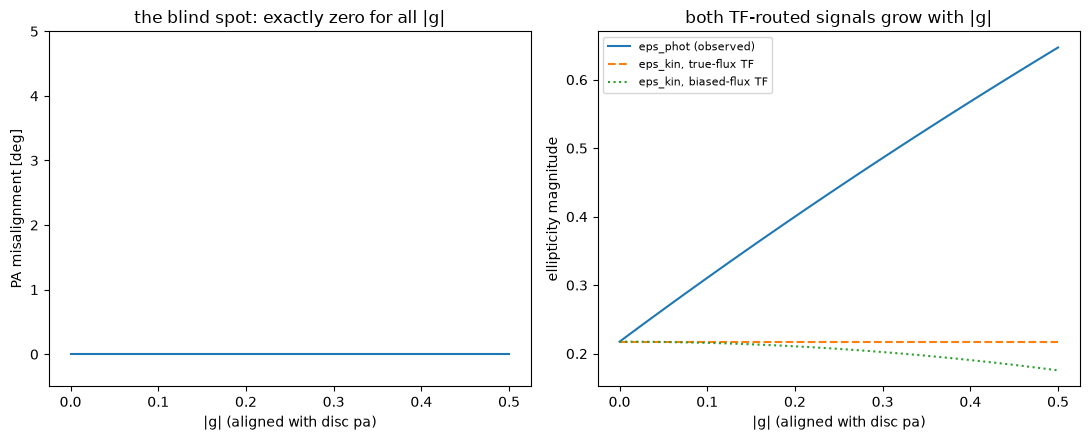

In [8]:
g_mags = np.linspace(0, 0.5, 60)
pa_mis, eps_phot_curve, eps_kin_true_curve, eps_kin_biased_curve, mu_curve = [], [], [], [], []

for gm in g_mags:
    gc = gm * np.exp(2j * phi_gal)
    sc = apply_shear(gal, gc.real, gc.imag)
    m_obs, p_obs = sc.photometric_ellipticity
    pa_mis.append(min(abs(p_obs - gal.pa), 180 - abs(p_obs - gal.pa)))
    eps_phot_curve.append(m_obs)

    mu_g = magnification(gc.real, gc.imag)
    mu_curve.append(mu_g)
    vft = tf_velocity(gal.flux, v0=gal.v_flat, flux0=gal.flux)
    vfb = tf_velocity(mu_g * gal.flux, v0=gal.v_flat, flux0=gal.flux)
    eps_kin_true_curve.append(
        eps_from_inclination(np.degrees(np.arcsin(np.clip(v_max_true / vft, -1, 1))))
    )
    eps_kin_biased_curve.append(
        eps_from_inclination(np.degrees(np.arcsin(np.clip(v_max_true / vfb, -1, 1))))
    )

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

axes[0].plot(g_mags, pa_mis)
axes[0].set_xlabel("|g| (aligned with disc pa)")
axes[0].set_ylabel("PA misalignment [deg]")
axes[0].set_title("the blind spot: exactly zero for all |g|")
axes[0].set_ylim(-0.5, 5)

axes[1].plot(g_mags, eps_phot_curve, label="eps_phot (observed)")
axes[1].plot(g_mags, eps_kin_true_curve, "--", label="eps_kin, true-flux TF")
axes[1].plot(g_mags, eps_kin_biased_curve, ":", label="eps_kin, biased-flux TF")
axes[1].set_xlabel("|g| (aligned with disc pa)")
axes[1].set_ylabel("ellipticity magnitude")
axes[1].set_title("both TF-routed signals grow with |g|")
axes[1].legend(fontsize=8)

fig.tight_layout()

## What this means, and what's next

Even in the PA-blind-spot case, the ellipticity-magnitude gap
(`eps_phot - eps_kin_true`) is a real, nonzero shear signal, and it's
exactly the quantity a magnitude-only version of the Huff et al. shear
estimator would use. The magnification-driven TF bias
(`eps_kin_true` vs. `eps_kin_biased`) is a separate systematic on top of
that -- in a real analysis it would need either an independent
convergence estimate or a joint fit, not the "TF on raw observed flux"
shortcut used here for illustration.

- `kino.instruments` (Phase 3) and `kino.inference` (Phase 5): a real
  measurement doesn't get `v_max` for free -- it comes from fitting a
  noisy, resolution-limited spectrum, and the *real* Tully-Fisher relation
  (calibration, band, intrinsic scatter) has to come from outside KINO.
- The magnification bias here assumes flux is measured perfectly; real
  photometry has its own uncertainties that would fold in alongside it.
- See `02_shear_misalignment_demo.ipynb` for the complementary PA-based
  signal, which this notebook's whole premise is that it *doesn't* cover.